# RankUp TabM — Sweep Fraksi Label

Notebook Kaggle ini menjalankan **TabM** pada lima dataset ordinal dengan semi-supervised learning **RankUp**. Empat skenario augmentasi weak/strong dibandingkan:

1. **RankUp + Range-Limited** — sel terpilih diganti nilai acak dalam bin kuantil lokal tempat nilai asli berada; implementasi setia `BinSampling` pada repo resmi paper (KDD 2025).
2. **RankUp + SCARF** — sebagian fitur diganti nilai dari distribusi marginal fitur yang sama (ICLR 2021).
3. **RankUp + TabCutMix** — sebagian sel fitur ditukar dengan baris donor yang pseudo-labelnya sama/terdekat, dicocokkan lewat confidence prediksi model (2024).
4. **RankUp + Gaussian Noise** — injeksi noise Gaussian pada fitur numerik (2021).

Setiap eksperimen dijalankan pada fraksi label train **1%, 10%, dan 30%**, disertai baseline **Supervised** dengan jumlah label yang sama dan **Fully-Supervised** (semua label train) sebagai upper bound. Seluruh eksperimen diulang pada daftar seed yang dapat diatur pada konfigurasi, lalu dilaporkan sebagai mean ± std.

Metrik test: **R² ↑, Spearman ↑, MAE ↓, RMSE ↓, QWK ↑**.

## 1. Setup

In [1]:
%pip install -q tabm

import gc
import random
import time
from itertools import cycle, islice
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import spearmanr
from sklearn.metrics import (
    cohen_kappa_score, mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tabm import TabM
from torch.utils.data import DataLoader, TensorDataset

sns.set_theme(style="whitegrid", context="notebook")

SEEDS = [42, 123, 456, 789, 101112]
LABELED_FRACTIONS = [0.01, 0.10, 0.30]

EPOCHS = 120
BATCH_SIZE = 32
SUPERVISED_BATCH_SIZE = 256
MAX_RANKUP_STEPS = 100
LOG_EVERY = 10
W_RANK = 0.2
W_UNLABELED = 0.2
P_CUTOFF = 0.95

WEAK_PROBABILITY = 0.1                 # dipakai RLA, SCARF, dan TabCutMix weak
RLA_NUM_BINS = 4                       # default paper (BinSampling num_bins=4)
RLA_STRONG_PROBABILITY = 0.3           # alpha default paper
GAUSSIAN_WEAK_SIGMA = 0.05             # satuan SD karena fitur terstandardisasi
GAUSSIAN_STRONG_SIGMA = 0.20
SCARF_STRONG_PROBABILITY = 0.6         # corruption rate default paper SCARF
TABCUTMIX_STRONG_PROBABILITY = 0.5     # fraksi tukar fitur strong view TabCutMix
DONOR_MIN_CONFIDENCE = 0.8             # ambang confidence kandidat donor TabCutMix

DATASET_FILES = {
    "Melbourne Airbnb": "oc10_melbourneAirbnb.csv",
    "Student Performance": "oc08_studentPerformance.csv",
    "NHANES": "oc05_nhanes.csv",
    "ESL": "oc06_esl.csv",
    "LEV": "oc05_lev.csv",
}
FRACTION_EXPERIMENTS = [
    "Supervised",
    "RankUp + Range-Limited",
    "RankUp + SCARF",
    "RankUp + TabCutMix",
    "RankUp + Gaussian Noise",
]
ALL_EXPERIMENTS = ["Fully-Supervised", *FRACTION_EXPERIMENTS]
METRICS = ["R2", "Spearman", "MAE", "RMSE", "QWK"]

WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
OUTPUT_DIR = WORK_DIR / "rankup_tabm_fraction_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
HARDWARE = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print(f"Device: {DEVICE} | {HARDWARE}")
print(f"Seeds: {SEEDS}")
print(f"Fraksi label: {LABELED_FRACTIONS}")

Note: you may need to restart the kernel to use updated packages.
Device: cuda:0 | Tesla T4
Seeds: [42, 123, 456, 789, 101112]
Fraksi label: [0.01, 0.1, 0.3]


## 2. Memuat seluruh dataset

Pencarian file mendukung struktur lokal `dataset/` dan folder Kaggle `/kaggle/input/`. Semua fitur harus numerik dan target harus bernama `y` dengan kelas ordinal berurutan mulai dari 0.

In [2]:
def find_dataset(filename):
    for root in [Path("dataset"), Path("/kaggle/input"), Path("/kaggle/working")]:
        if root.exists():
            match = next(root.rglob(filename), None)
            if match is not None:
                return match
    raise FileNotFoundError(f"{filename} tidak ditemukan")


datasets = {}
for name, filename in DATASET_FILES.items():
    path = find_dataset(filename)
    df = pd.read_csv(path)
    if "y" not in df.columns or df.isna().any().any():
        raise ValueError(f"{name}: target 'y' wajib ada dan data tidak boleh missing")
    if len(df.select_dtypes(include=np.number).columns) != len(df.columns):
        raise ValueError(f"{name}: semua kolom harus numerik")
    classes = np.sort(df["y"].unique())
    if not np.array_equal(classes, np.arange(len(classes))):
        raise ValueError(f"{name}: kelas harus 0..K-1, ditemukan {classes.tolist()}")
    datasets[name] = df
    print(f"{name:20} | {df.shape[0]:6,} baris | {df.shape[1] - 1:2} fitur | {len(classes)} kelas")

Melbourne Airbnb     | 20,036 baris | 48 fitur | 10 kelas
Student Performance  |    662 baris | 43 fitur | 8 kelas
NHANES               |  5,223 baris | 30 fitur | 5 kelas
ESL                  |    488 baris |  4 fitur | 6 kelas
LEV                  |  1,000 baris |  4 fitur | 5 kelas


## 3. Split, preprocessing, dan evaluasi

Split test 80/20 stratified per seed; di dalam train, `labeled_fraction` data diberi label secara stratified dan sisanya menjadi unlabeled. Jika sebuah fraksi menghasilkan label lebih sedikit daripada jumlah kelas, jumlah label diangkat menjadi minimal satu per kelas agar split stratified tetap mungkin; jumlah final tercatat pada kolom `n_labeled`. Target regresi distandardisasi memakai scaler yang di-fit pada subset labeled saja. Fully-Supervised tidak bergantung fraksi sehingga hanya dijalankan sekali per seed.

In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def prepare_data(df, fraction, seed):
    X = df.drop(columns="y").to_numpy(dtype=np.float32)
    y = df["y"].to_numpy(dtype=np.float32)
    indices = np.arange(len(df))
    train_idx, test_idx = train_test_split(
        indices, test_size=0.2, random_state=seed, stratify=y
    )
    n_classes = len(np.unique(y))
    n_requested = round(fraction * len(train_idx))
    n_labeled = max(n_classes, n_requested)
    if n_labeled > n_requested:
        print(f"Fraksi {fraction:.0%} = {n_requested} label < {n_classes} kelas; diangkat menjadi {n_labeled} label")
    labeled_idx, unlabeled_idx = train_test_split(
        train_idx, train_size=n_labeled, random_state=seed, stratify=y[train_idx]
    )

    x_scaler = StandardScaler().fit(X[train_idx])
    y_scaler = StandardScaler().fit(y[labeled_idx, None])
    X_scaled = x_scaler.transform(X).astype(np.float32)
    y_scaled = y_scaler.transform(y[:, None]).astype(np.float32)

    tensor = torch.from_numpy
    return {
        "x_labeled": tensor(X_scaled[labeled_idx]),
        "y_labeled": tensor(y_scaled[labeled_idx]),
        "x_unlabeled": tensor(X_scaled[unlabeled_idx]),
        "x_train": tensor(X_scaled[train_idx]),
        "y_train": tensor(y_scaled[train_idx]),
        "x_test": tensor(X_scaled[test_idx]),
        "y_test": y[test_idx].astype(int),
        "y_scaler": y_scaler,
        "n_features": X.shape[1],
        "class_min": int(y.min()),
        "class_max": int(y.max()),
    }


def evaluate(y_true, score, class_min, class_max):
    prediction = np.clip(np.rint(score), class_min, class_max).astype(int)
    spearman = spearmanr(y_true, score).statistic
    return {
        "R2": r2_score(y_true, score),
        "Spearman": 0.0 if np.isnan(spearman) else spearman,
        "MAE": mean_absolute_error(y_true, score),
        "RMSE": mean_squared_error(y_true, score) ** 0.5,
        "QWK": cohen_kappa_score(y_true, prediction, weights="quadratic"),
    }


def mean_std_table(frame, group_columns):
    mean = frame.groupby(group_columns)[METRICS].mean()
    std = frame.groupby(group_columns)[METRICS].std()
    table = mean.copy().astype(object)
    for metric in METRICS:
        table[metric] = [
            f"{m:.4f} ± {s:.4f}" if pd.notna(s) else f"{m:.4f}"
            for m, s in zip(mean[metric], std[metric])
        ]
    return table.reset_index()

## 4. Model, augmentasi, dan loss RankUp

TabM memakai `d_out=3`: satu output regresi dan dua logit ranking. Loss anggota ensemble dihitung independen; prediksi dirata-ratakan saat inference. Empat pembuat weak/strong view:

- **Range-Limited**: setia `BinSampling` pada repo resmi paper — tiap fitur dibagi menjadi `RLA_NUM_BINS` bin kuantil; sel yang lolos mask Bernoulli diganti nilai acak seragam **di dalam bin yang sama dengan nilai aslinya**, sehingga gangguan selalu lokal dan semantik sampel terjaga. Sel tepat sama dengan maksimum train dibiarkan (konvensi kode resmi). Di paper, RLA dipakai sebagai augmentasi kontrastive dengan alpha=0.3 dan 4 bin; di sini dipakai sebagai weak/strong view dengan probabilitas mask kecil/besar.
- **SCARF**: setia Algorithm 1 paper — tiap baris memilih tepat `q = max(1, ⌊rate·M⌋)` fitur secara acak, lalu fitur terpilih diganti draw i.i.d. dari **marginal empiris fitur itu di seluruh train set** (`marginal[acak, j]`). Rate: weak 0.1, strong 0.6 (default paper). Pemakaian kontrastive paper diadaptasi menjadi view RankUp.
- **TabCutMix**: adaptasi same-class paper untuk data unlabeled via **pseudo-label donor matching** — tiap langkah, model memprediksi batch unlabeled (no-grad) menghasilkan pseudo-label ordinal (skor regresi di-inverse-transform lalu dibulatkan ke kelas) dan confidence (kedekatan ke pusat kelas: `1 − 2·|score − round|`). Hanya sampel dengan confidence ≥ `DONOR_MIN_CONFIDENCE` menjadi kandidat donor; tiap baris dicocokkan dengan donor berpseudo-rank sama atau terdekat, lalu dicampur `x_mix = M⊙x_a + (1−M)⊙x_b` dengan mask elemen ~Bernoulli(p): weak p=0.1, strong p=0.5. Baris tanpa donor lolos tanpa campuran; ground-truth tidak pernah menyentuh cabang unlabeled. Deviasi dari paper yang didokumentasikan: same-class ground-truth diganti pseudo-label matching, dan λ~U(0,1) diganti probabilitas weak/strong tetap agar hierarki augmentasi terjaga.
- **Gaussian Noise**: `x̂ = x + ε`, `ε ~ N(0, σ²)` dalam satuan SD data terstandardisasi; weak memakai σ kecil, strong lebih besar.

Loss regresi L1, ranking pasangan supervised, dan pseudo-ranking confidence-filtered identik untuk keempat augmentasi.

In [4]:
class TabMRankUp(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.model = TabM.make(n_num_features=n_features, d_out=3)

    def forward(self, x):
        output = self.model(x)             # (batch, k, 3)
        return output[..., :1], output[..., 1:]


def range_limited_edges(x_train, n_bins=RLA_NUM_BINS):
    quantiles = torch.linspace(0, 1, n_bins + 1, device=x_train.device)
    return torch.quantile(x_train, quantiles, dim=0)   # (n_bins + 1, n_features)


def range_limited_view(x, edges, probability):
    n_bins = edges.shape[0] - 1
    bin_id = torch.stack([
        torch.bucketize(x[:, j].contiguous(), edges[:, j].contiguous(), right=True) - 1
        for j in range(x.shape[1])
    ], dim=1).clamp(min=0)                             # bin milik nilai asli, per fitur
    safe_id = bin_id.clamp(max=n_bins - 1)
    column = torch.arange(edges.shape[1], device=x.device)
    low = edges[safe_id, column]
    high = edges[safe_id + 1, column]
    sampled = low + torch.rand_like(x) * (high - low)  # seragam di dalam bin asal
    corrupted = torch.where(torch.rand_like(x) < probability, sampled, x)
    return torch.where(bin_id == n_bins, x, corrupted) # nilai tepat maksimum: tetap asli


def scarf_view(x, marginal, rate):
    n_corrupt = max(1, int(rate * x.shape[1]))         # paper: q = ⌊c·M⌋ (floor); 0 diangkat ke 1
    order = torch.rand_like(x).argsort(dim=1)          # urutan acak indeks fitur per baris
    mask = torch.zeros_like(x, dtype=torch.bool)
    mask.scatter_(1, order[:, :n_corrupt], True)       # tepat q fitur berbeda per baris
    column = torch.arange(x.shape[1], device=x.device)
    draw = marginal[torch.randint(len(marginal), x.shape, device=x.device), column]
    return torch.where(mask, draw, x)                  # i.i.d. dari marginal empiris train


def ordinal_pseudo_label(scores, y_scale, y_mean, class_min, class_max):
    scores = scores.flatten()                          # terima (B,) maupun (B,1) dari mean ensemble
    score = scores * y_scale + y_mean                  # kembali ke satuan kelas asli
    pseudo = torch.clamp(torch.round(score), class_min, class_max)
    confidence = (1.0 - 2.0 * (score - pseudo).abs()).clamp(min=0.0)
    return pseudo, confidence                          # 1 di pusat kelas, 0 di batas antarkelas


def match_donors(pseudo, confidence, threshold):
    valid = confidence >= threshold
    if int(valid.sum()) < 2:
        return torch.arange(len(pseudo), device=pseudo.device), torch.zeros_like(valid)
    distance = (pseudo[:, None] - pseudo[None, :]).abs()
    distance = distance.masked_fill(~valid, float("inf"))
    distance.fill_diagonal_(float("inf"))              # jangan jadi donor diri sendiri
    donor_idx = distance.argmin(dim=1)                 # pseudo-rank sama, atau terdekat
    nearest = distance.gather(1, donor_idx[:, None]).squeeze(1)
    return donor_idx, torch.isfinite(nearest)


def tabcutmix_pair(x, donor_idx, has_donor, probability):
    donor = x[donor_idx]
    mask = (torch.rand_like(x) < probability) & has_donor[:, None]
    return torch.where(mask, donor, x)                 # M⊙x_a + (1−M)⊙x_b; tanpa donor -> tetap


def tabcutmix_views(y_scale, y_mean, class_min, class_max):
    def views(x_u, scores=None):
        pseudo, confidence = ordinal_pseudo_label(scores, y_scale, y_mean, class_min, class_max)
        donor_idx, has_donor = match_donors(pseudo, confidence, DONOR_MIN_CONFIDENCE)
        weak = tabcutmix_pair(x_u, donor_idx, has_donor, WEAK_PROBABILITY)
        strong = tabcutmix_pair(x_u, donor_idx, has_donor, TABCUTMIX_STRONG_PROBABILITY)
        return weak, strong
    return views


def range_limited_views(edges):
    def views(x_u, scores=None):
        weak = range_limited_view(x_u, edges, WEAK_PROBABILITY)
        strong = range_limited_view(x_u, edges, RLA_STRONG_PROBABILITY)
        return weak, strong
    return views


def scarf_views(marginal):
    def views(x_u, scores=None):
        weak = scarf_view(x_u, marginal, WEAK_PROBABILITY)
        strong = scarf_view(x_u, marginal, SCARF_STRONG_PROBABILITY)
        return weak, strong
    return views


def gaussian_views(x_u, scores=None):
    weak = x_u + torch.randn_like(x_u) * GAUSSIAN_WEAK_SIGMA
    strong = x_u + torch.randn_like(x_u) * GAUSSIAN_STRONG_SIGMA
    return weak, strong


def build_views(experiment, data):
    if experiment == "RankUp + Range-Limited":
        return range_limited_views(range_limited_edges(data["x_train"]).to(DEVICE))
    if experiment == "RankUp + SCARF":
        return scarf_views(data["x_train"].to(DEVICE))
    if experiment == "RankUp + TabCutMix":
        return tabcutmix_views(
            float(data["y_scaler"].scale_[0]), float(data["y_scaler"].mean_[0]),
            data["class_min"], data["class_max"],
        )
    if experiment == "RankUp + Gaussian Noise":
        return gaussian_views
    return tabcutmix_views


def regression_loss(prediction, target):
    if prediction.ndim == 3:
        target = target[:, None, :].expand_as(prediction)
    return F.l1_loss(prediction, target)


def pairwise_logits(rank_logits):
    if rank_logits.ndim == 2:
        return rank_logits[:, None, :] - rank_logits[None, :, :]
    rank_logits = rank_logits.permute(1, 0, 2)
    return rank_logits[:, :, None, :] - rank_logits[:, None, :, :]


def pairwise_targets(target):
    difference = target[:, None, 0] - target[None, :, 0]
    probability = (difference > 0).float() + 0.5 * (difference == 0).float()
    return torch.stack([1 - probability, probability], dim=-1)


def supervised_rank_loss(rank_logits, target):
    logits = pairwise_logits(rank_logits)
    targets = pairwise_targets(target)
    if logits.ndim == 4:
        targets = targets.unsqueeze(0).expand(logits.shape[0], -1, -1, -1)
    return F.cross_entropy(logits.reshape(-1, 2), targets.reshape(-1, 2))


def pseudo_rank_loss(weak_logits, strong_logits):
    weak_pairs = pairwise_logits(weak_logits)
    weak_probability = F.softmax(weak_pairs, dim=-1)
    if weak_probability.ndim == 4:
        weak_probability = weak_probability.mean(0)
    confidence, pseudo_target = weak_probability.max(dim=-1)

    strong_pairs = pairwise_logits(strong_logits)
    if strong_pairs.ndim == 4:
        pseudo_target = pseudo_target.unsqueeze(0).expand(strong_pairs.shape[0], -1, -1)
        confidence = confidence.unsqueeze(0).expand(strong_pairs.shape[0], -1, -1)
    loss = F.cross_entropy(
        strong_pairs.reshape(-1, 2), pseudo_target.reshape(-1), reduction="none"
    )
    mask = confidence.reshape(-1) >= P_CUTOFF
    return (loss[mask].mean() if mask.any() else loss.sum() * 0), mask.float().mean().item()


def make_loader(*tensors, batch_size=BATCH_SIZE, shuffle=True, seed=SEEDS[0]):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        TensorDataset(*tensors), batch_size=batch_size, shuffle=shuffle,
        generator=generator, pin_memory=torch.cuda.is_available(),
    )


def predict(model, data):
    loader = make_loader(data["x_test"], batch_size=1024, shuffle=False)
    predictions = []
    model.eval()
    with torch.inference_mode():
        for (x,) in loader:
            prediction, _ = model(x.to(DEVICE, non_blocking=True))
            if prediction.ndim == 3:
                prediction = prediction.mean(dim=1)
            predictions.append(prediction.cpu().numpy())
    scaled = np.concatenate(predictions).reshape(-1, 1)
    return data["y_scaler"].inverse_transform(scaled).ravel()


demo_x = torch.tensor([[0.0, 1.0], [1.0, 0.0], [2.0, 2.0]])
demo_y = torch.tensor([[0.0], [1.0], [2.0]])
demo_low = demo_x.min(dim=0).values
demo_high = demo_x.max(dim=0).values
assert pairwise_targets(demo_y)[2, 0, 1] == 1
rla_demo = range_limited_view(demo_x, range_limited_edges(demo_x, 2), 0.5)
assert rla_demo.shape == demo_x.shape and (rla_demo >= demo_low).all() and (rla_demo <= demo_high).all()
scarf_demo = scarf_view(demo_x, demo_x, 0.5)
q_demo = max(1, int(0.5 * demo_x.shape[1]))
assert scarf_demo.shape == demo_x.shape and ((scarf_demo != demo_x).sum(dim=1) <= q_demo).all()
demo_scores = torch.tensor([[0.5], [1.25], [0.54]])    # skor regresi terstandardisasi
pseudo_demo, conf_demo = ordinal_pseudo_label(demo_scores, 2.0, 0.0, 0, 4)
assert pseudo_demo.flatten().tolist() == [1.0, 2.0, 1.0]
assert conf_demo.flatten().tolist()[0] == 1.0 and conf_demo.flatten().tolist()[1] == 0.0
idx_demo, ok_demo = match_donors(pseudo_demo.flatten(), conf_demo, 0.8)
assert idx_demo.tolist() == [2, 0, 0] and ok_demo.tolist() == [True, True, True]
assert pseudo_demo[idx_demo[0]] == pseudo_demo[0]      # donor ber-pseudo-rank sama; sampel low-conf tetap boleh menerima
x3 = torch.randn(3, 2)
assert torch.equal(tabcutmix_pair(x3, idx_demo, ok_demo, 0.0), x3)          # p=0: identik
mixed_demo = tabcutmix_pair(x3, idx_demo, ok_demo, 1.0)                     # p=1: seluruh sel baris berdonor menjadi donor
assert torch.equal(mixed_demo[0], x3[2]) and torch.equal(mixed_demo[1], x3[0]) and torch.equal(mixed_demo[2], x3[0])
assert gaussian_views(demo_x)[0].shape == demo_x.shape
print("Self-check empat augmentasi dan loss RankUp: OK")

Self-check empat augmentasi dan loss RankUp: OK


## 5. Training dan runner

Supervised dan Fully-Supervised memakai fungsi training yang sama (hanya beda sumber label dan batch size); keempat eksperimen RankUp memakai satu loop training yang sama dan hanya beda pembuat weak/strong view.

In [5]:
def train_supervised(x, y, batch_size, seed):
    set_seed(seed)
    model = TabMRankUp(x.shape[1]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=3e-4)
    loader = make_loader(x, y, batch_size=batch_size, seed=seed)
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        losses = []
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction, _ = model(xb)
            loss = regression_loss(prediction, yb)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        history.append({"epoch": epoch, "loss": np.mean(losses)})
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == EPOCHS:
            print(f"  epoch {epoch:03d}/{EPOCHS} | loss={np.mean(losses):.4f}")
    return model, history


def train_rankup(data, make_views, seed, needs_scores=False):
    set_seed(seed)
    model = TabMRankUp(data["n_features"]).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=3e-4)
    labeled_loader = make_loader(data["x_labeled"], data["y_labeled"], seed=seed)
    unlabeled_loader = make_loader(data["x_unlabeled"], seed=seed)
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        totals, rank_labs, rank_unlabs, accepted = [], [], [], []
        labeled_batches = cycle(labeled_loader)
        for (x_u,) in islice(unlabeled_loader, MAX_RANKUP_STEPS):
            x_l, y_l = next(labeled_batches)
            x_l, y_l, x_u = x_l.to(DEVICE), y_l.to(DEVICE), x_u.to(DEVICE)
            if needs_scores:                       # hanya TabCutMix yang butuh pseudo-label donor
                with torch.no_grad():
                    prediction_u, _ = model(x_u)
                scores_u = prediction_u.mean(dim=1)
            else:
                scores_u = None
            weak, strong = make_views(x_u, scores_u)

            optimizer.zero_grad(set_to_none=True)
            pred_l, rank_l = model(x_l)
            loss_reg = regression_loss(pred_l, y_l)
            loss_rank_lab = supervised_rank_loss(rank_l, y_l)
            with torch.no_grad():
                _, rank_weak = model(weak)
            _, rank_strong = model(strong)
            loss_rank_unlab, accept_rate = pseudo_rank_loss(rank_weak, rank_strong)
            loss = loss_reg + W_RANK * loss_rank_lab + W_UNLABELED * loss_rank_unlab
            loss.backward()
            optimizer.step()

            totals.append(loss.item())
            rank_labs.append(loss_rank_lab.item())
            rank_unlabs.append(loss_rank_unlab.item())
            accepted.append(accept_rate)
        history.append({"epoch": epoch, "loss": np.mean(totals), "rank_labeled": np.mean(rank_labs), "rank_unlabeled": np.mean(rank_unlabs), "accepted": np.mean(accepted)})
        if epoch == 1 or epoch % LOG_EVERY == 0 or epoch == EPOCHS:
            print(f"  epoch {epoch:03d}/{EPOCHS} | loss={np.mean(totals):.4f} | accepted={np.mean(accepted):.1%}")
    return model, history


results, histories = [], []


def run_experiment(dataset_name, data, experiment, fraction, seed):
    started = time.perf_counter()
    if experiment == "Fully-Supervised":
        model, history = train_supervised(data["x_train"], data["y_train"], SUPERVISED_BATCH_SIZE, seed)
    elif experiment == "Supervised":
        model, history = train_supervised(data["x_labeled"], data["y_labeled"], BATCH_SIZE, seed)
    else:
        model, history = train_rankup(
            data, build_views(experiment, data), seed,
            needs_scores=(experiment == "RankUp + TabCutMix"),
        )
    training_seconds = time.perf_counter() - started

    inference_started = time.perf_counter()
    score = predict(model, data)
    inference_seconds = time.perf_counter() - inference_started

    metrics = evaluate(data["y_test"], score, data["class_min"], data["class_max"])
    results.append({
        "dataset": dataset_name, "experiment": experiment,
        "labeled_fraction": fraction, "n_labeled": len(data["x_labeled"]),
        "seed": seed, "hardware": HARDWARE,
        "training_seconds": training_seconds, "inference_seconds": inference_seconds,
        **metrics,
    })
    histories.extend({"dataset": dataset_name, "experiment": experiment, "seed": seed, **row} for row in history)
    pd.DataFrame(results).to_csv(OUTPUT_DIR / "metrics.csv", index=False)
    pd.DataFrame(histories).to_csv(OUTPUT_DIR / "history.csv", index=False)
    print(pd.Series(metrics).round(4).to_dict())
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# 6. Eksperimen

Setiap eksperimen punya sel eksekusi sendiri sehingga bisa dimonitor dan diulang secara terpisah; urutan mengikuti notebook acuan: Supervised, Fully-Supervised, lalu empat RankUp. CSV sudah tersimpan ulang setiap run, jadi sesi yang terputus tidak merusak hasil sebelumnya.

## 6.1 Supervised

Baseline dengan hanya label sebanyak `labeled_fraction` dari train; jumlah labelnya identik dengan skenario RankUp pada fraksi yang sama.

In [6]:
experiment = "Supervised"
for dataset_name, df in datasets.items():
    print(f"\n=== {dataset_name} | {experiment} ===")
    for seed in SEEDS:
        for fraction in LABELED_FRACTIONS:
            data = prepare_data(df, fraction, seed)
            print(f"\n{dataset_name} | seed={seed} | fraksi={fraction:.0%} | labeled={len(data['x_labeled'])}")
            run_experiment(dataset_name, data, experiment, fraction, seed)

results_df = pd.DataFrame(results)
history_df = pd.DataFrame(histories)
display(results_df.query("experiment == @experiment").tail())


=== Melbourne Airbnb | Supervised ===

Melbourne Airbnb | seed=42 | fraksi=1% | labeled=160
  epoch 001/120 | loss=0.8548
  epoch 010/120 | loss=0.3878
  epoch 020/120 | loss=0.2769
  epoch 030/120 | loss=0.2182
  epoch 040/120 | loss=0.1928
  epoch 050/120 | loss=0.1712
  epoch 060/120 | loss=0.1630
  epoch 070/120 | loss=0.1534
  epoch 080/120 | loss=0.1389
  epoch 090/120 | loss=0.1328
  epoch 100/120 | loss=0.1263
  epoch 110/120 | loss=0.1277
  epoch 120/120 | loss=0.1201
{'R2': 0.5709, 'Spearman': 0.7517, 'MAE': 1.5276, 'RMSE': 1.9677, 'QWK': 0.7267}

Melbourne Airbnb | seed=42 | fraksi=10% | labeled=1603
  epoch 001/120 | loss=0.5802
  epoch 010/120 | loss=0.4149
  epoch 020/120 | loss=0.3674
  epoch 030/120 | loss=0.3157
  epoch 040/120 | loss=0.2826
  epoch 050/120 | loss=0.2599
  epoch 060/120 | loss=0.2479
  epoch 070/120 | loss=0.2321
  epoch 080/120 | loss=0.2226
  epoch 090/120 | loss=0.2136
  epoch 100/120 | loss=0.2061
  epoch 110/120 | loss=0.2017
  epoch 120/120 | lo

,dataset,experiment,labeled_fraction,n_labeled,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
70,LEV,Supervised,0.10,80,789,Tesla T4,1.149814,0.004066,0.404019,0.646751,0.525421,0.734160,0.597974
71,LEV,Supervised,0.30,240,789,Tesla T4,2.987660,0.004154,0.438715,0.683104,0.457699,0.712469,0.671477
72,LEV,Supervised,0.01,8,101112,Tesla T4,0.392724,0.004057,0.009301,0.384504,0.732168,0.946553,0.334772
73,LEV,Supervised,0.10,80,101112,Tesla T4,1.124849,0.004052,0.305130,0.668384,0.564405,0.792732,0.614092
74,LEV,Supervised,0.30,240,101112,Tesla T4,3.014299,0.004163,0.198231,0.618555,0.581301,0.851528,0.495324


## 6.2 Fully-Supervised

Semua label train dipakai sebagai upper bound; tidak bergantung fraksi sehingga cukup sekali per seed.

In [7]:
experiment = "Fully-Supervised"
for dataset_name, df in datasets.items():
    print(f"\n=== {dataset_name} | {experiment} ===")
    for seed in SEEDS:
        data = prepare_data(df, LABELED_FRACTIONS[0], seed)
        print(f"\n{dataset_name} | seed={seed}")
        run_experiment(dataset_name, data, experiment, 1.0, seed)

results_df = pd.DataFrame(results)
history_df = pd.DataFrame(histories)
display(results_df.query("experiment == @experiment").tail())


=== Melbourne Airbnb | Fully-Supervised ===

Melbourne Airbnb | seed=42
  epoch 001/120 | loss=0.5266
  epoch 010/120 | loss=0.3984
  epoch 020/120 | loss=0.3733
  epoch 030/120 | loss=0.3565
  epoch 040/120 | loss=0.3452
  epoch 050/120 | loss=0.3349
  epoch 060/120 | loss=0.3276
  epoch 070/120 | loss=0.3209
  epoch 080/120 | loss=0.3162
  epoch 090/120 | loss=0.3114
  epoch 100/120 | loss=0.3079
  epoch 110/120 | loss=0.3041
  epoch 120/120 | loss=0.3016
{'R2': 0.7438, 'Spearman': 0.8589, 'MAE': 1.0796, 'RMSE': 1.5203, 'QWK': 0.8541}

Melbourne Airbnb | seed=123
  epoch 001/120 | loss=0.5207
  epoch 010/120 | loss=0.3967
  epoch 020/120 | loss=0.3701
  epoch 030/120 | loss=0.3543
  epoch 040/120 | loss=0.3423
  epoch 050/120 | loss=0.3320
  epoch 060/120 | loss=0.3249
  epoch 070/120 | loss=0.3185
  epoch 080/120 | loss=0.3132
  epoch 090/120 | loss=0.3092
  epoch 100/120 | loss=0.3049
  epoch 110/120 | loss=0.3018
  epoch 120/120 | loss=0.2986
{'R2': 0.7177, 'Spearman': 0.8469, 'M

,dataset,experiment,labeled_fraction,n_labeled,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
95,LEV,Fully-Supervised,1.0,8,42,Tesla T4,5.354219,0.004280,0.494232,0.732101,0.429150,0.676317,0.701538
96,LEV,Fully-Supervised,1.0,8,123,Tesla T4,5.345501,0.004213,0.347775,0.609173,0.531266,0.768021,0.571080
97,LEV,Fully-Supervised,1.0,8,456,Tesla T4,5.345890,0.004322,0.480887,0.706306,0.461089,0.685181,0.646076
98,LEV,Fully-Supervised,1.0,8,789,Tesla T4,5.346435,0.004328,0.619585,0.786163,0.372506,0.586547,0.751103
99,LEV,Fully-Supervised,1.0,8,101112,Tesla T4,5.362564,0.004304,0.507733,0.738167,0.432941,0.667228,0.707862


## 6.3 RankUp + Range-Limited

Weak/strong view dari sampling ulang dalam bin kuantil lokal tempat nilai asli berada; setia `BinSampling` pada repo resmi paper (4 bin, mask Bernoulli).

In [8]:
experiment = "RankUp + Range-Limited"
for dataset_name, df in datasets.items():
    print(f"\n=== {dataset_name} | {experiment} ===")
    for seed in SEEDS:
        for fraction in LABELED_FRACTIONS:
            data = prepare_data(df, fraction, seed)
            print(f"\n{dataset_name} | seed={seed} | fraksi={fraction:.0%} | labeled={len(data['x_labeled'])}")
            run_experiment(dataset_name, data, experiment, fraction, seed)

results_df = pd.DataFrame(results)
history_df = pd.DataFrame(histories)
display(results_df.query("experiment == @experiment").tail())


=== Melbourne Airbnb | RankUp + Range-Limited ===

Melbourne Airbnb | seed=42 | fraksi=1% | labeled=160
  epoch 001/120 | loss=0.5604 | accepted=15.0%
  epoch 010/120 | loss=0.1504 | accepted=55.0%
  epoch 020/120 | loss=0.1245 | accepted=58.9%
  epoch 030/120 | loss=0.1124 | accepted=61.4%
  epoch 040/120 | loss=0.1035 | accepted=62.1%
  epoch 050/120 | loss=0.0970 | accepted=63.1%
  epoch 060/120 | loss=0.0965 | accepted=63.3%
  epoch 070/120 | loss=0.0897 | accepted=63.7%
  epoch 080/120 | loss=0.0864 | accepted=64.5%
  epoch 090/120 | loss=0.0821 | accepted=64.8%
  epoch 100/120 | loss=0.0804 | accepted=65.6%
  epoch 110/120 | loss=0.0802 | accepted=65.4%
  epoch 120/120 | loss=0.0758 | accepted=65.8%
{'R2': 0.5827, 'Spearman': 0.7652, 'MAE': 1.4439, 'RMSE': 1.9405, 'QWK': 0.7569}

Melbourne Airbnb | seed=42 | fraksi=10% | labeled=1603
  epoch 001/120 | loss=0.6698 | accepted=12.5%
  epoch 010/120 | loss=0.4507 | accepted=36.4%
  epoch 020/120 | loss=0.3580 | accepted=40.2%
  epoc

,dataset,experiment,labeled_fraction,n_labeled,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
170,LEV,RankUp + Range-Limited,0.10,80,789,Tesla T4,22.119980,0.003925,0.260097,0.586848,0.576053,0.818016,0.570543
171,LEV,RankUp + Range-Limited,0.30,240,789,Tesla T4,17.656192,0.003901,0.398193,0.680813,0.453408,0.737739,0.647672
172,LEV,RankUp + Range-Limited,0.01,8,101112,Tesla T4,24.060285,0.004144,-0.015123,0.440709,0.744861,0.958150,0.422241
173,LEV,RankUp + Range-Limited,0.10,80,101112,Tesla T4,22.083901,0.003940,0.220759,0.656552,0.598921,0.839480,0.629229
174,LEV,RankUp + Range-Limited,0.30,240,101112,Tesla T4,17.516627,0.003900,0.118984,0.568773,0.604322,0.892619,0.498828


## 6.4 RankUp + SCARF

Weak/strong view dari korupsi tepat q fitur per baris dengan draw dari marginal empiris train (Algorithm 1 paper SCARF).

In [9]:
experiment = "RankUp + SCARF"
for dataset_name, df in datasets.items():
    print(f"\n=== {dataset_name} | {experiment} ===")
    for seed in SEEDS:
        for fraction in LABELED_FRACTIONS:
            data = prepare_data(df, fraction, seed)
            print(f"\n{dataset_name} | seed={seed} | fraksi={fraction:.0%} | labeled={len(data['x_labeled'])}")
            run_experiment(dataset_name, data, experiment, fraction, seed)

results_df = pd.DataFrame(results)
history_df = pd.DataFrame(histories)
display(results_df.query("experiment == @experiment").tail())


=== Melbourne Airbnb | RankUp + SCARF ===

Melbourne Airbnb | seed=42 | fraksi=1% | labeled=160
  epoch 001/120 | loss=0.5773 | accepted=15.6%
  epoch 010/120 | loss=0.2218 | accepted=38.9%
  epoch 020/120 | loss=0.1978 | accepted=42.1%
  epoch 030/120 | loss=0.1880 | accepted=44.2%
  epoch 040/120 | loss=0.1744 | accepted=45.9%
  epoch 050/120 | loss=0.1684 | accepted=45.0%
  epoch 060/120 | loss=0.1682 | accepted=45.9%
  epoch 070/120 | loss=0.1617 | accepted=46.1%
  epoch 080/120 | loss=0.1620 | accepted=45.7%
  epoch 090/120 | loss=0.1554 | accepted=46.6%
  epoch 100/120 | loss=0.1535 | accepted=47.2%
  epoch 110/120 | loss=0.1522 | accepted=46.8%
  epoch 120/120 | loss=0.1498 | accepted=47.3%
{'R2': 0.5994, 'Spearman': 0.7689, 'MAE': 1.4463, 'RMSE': 1.9011, 'QWK': 0.7532}

Melbourne Airbnb | seed=42 | fraksi=10% | labeled=1603
  epoch 001/120 | loss=0.6946 | accepted=14.4%
  epoch 010/120 | loss=0.5062 | accepted=26.3%
  epoch 020/120 | loss=0.4260 | accepted=27.0%
  epoch 030/12

,dataset,experiment,labeled_fraction,n_labeled,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
245,LEV,RankUp + SCARF,0.10,80,789,Tesla T4,20.918724,0.003955,0.389645,0.649352,0.520474,0.742960,0.585050
246,LEV,RankUp + SCARF,0.30,240,789,Tesla T4,16.453120,0.003832,0.405823,0.694788,0.455165,0.733048,0.640063
247,LEV,RankUp + SCARF,0.01,8,101112,Tesla T4,22.438875,0.004028,-0.180913,0.191104,0.808311,1.033435,0.233931
248,LEV,RankUp + SCARF,0.10,80,101112,Tesla T4,20.735600,0.004007,0.294485,0.648061,0.552117,0.798780,0.608862
249,LEV,RankUp + SCARF,0.30,240,101112,Tesla T4,16.506014,0.003887,0.129125,0.567059,0.605115,0.887467,0.491223


## 6.5 RankUp + TabCutMix

Donor dicocokkan lewat pseudo-label ordinal ber-confidence tinggi (adaptasi same-class untuk data unlabeled), lalu sel fitur ditukar mask Bernoulli weak/strong.

In [10]:
experiment = "RankUp + TabCutMix"
for dataset_name, df in datasets.items():
    print(f"\n=== {dataset_name} | {experiment} ===")
    for seed in SEEDS:
        for fraction in LABELED_FRACTIONS:
            data = prepare_data(df, fraction, seed)
            print(f"\n{dataset_name} | seed={seed} | fraksi={fraction:.0%} | labeled={len(data['x_labeled'])}")
            run_experiment(dataset_name, data, experiment, fraction, seed)

results_df = pd.DataFrame(results)
history_df = pd.DataFrame(histories)
display(results_df.query("experiment == @experiment").tail())


=== Melbourne Airbnb | RankUp + TabCutMix ===

Melbourne Airbnb | seed=42 | fraksi=1% | labeled=160
  epoch 001/120 | loss=0.5240 | accepted=26.1%
  epoch 010/120 | loss=0.1559 | accepted=56.4%
  epoch 020/120 | loss=0.1256 | accepted=60.6%
  epoch 030/120 | loss=0.1178 | accepted=61.6%
  epoch 040/120 | loss=0.1074 | accepted=62.4%
  epoch 050/120 | loss=0.1044 | accepted=62.5%
  epoch 060/120 | loss=0.1027 | accepted=63.6%
  epoch 070/120 | loss=0.0975 | accepted=63.7%
  epoch 080/120 | loss=0.0958 | accepted=63.4%
  epoch 090/120 | loss=0.0916 | accepted=63.9%
  epoch 100/120 | loss=0.0885 | accepted=64.7%
  epoch 110/120 | loss=0.0847 | accepted=65.6%
  epoch 120/120 | loss=0.0844 | accepted=65.1%
{'R2': 0.6062, 'Spearman': 0.7776, 'MAE': 1.3765, 'RMSE': 1.8849, 'QWK': 0.7808}

Melbourne Airbnb | seed=42 | fraksi=10% | labeled=1603
  epoch 001/120 | loss=0.6513 | accepted=22.6%
  epoch 010/120 | loss=0.4420 | accepted=37.1%
  epoch 020/120 | loss=0.3550 | accepted=39.5%
  epoch 03

,dataset,experiment,labeled_fraction,n_labeled,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
320,LEV,RankUp + TabCutMix,0.10,80,789,Tesla T4,23.031323,0.003864,0.383992,0.654290,0.513882,0.746393,0.601729
321,LEV,RankUp + TabCutMix,0.30,240,789,Tesla T4,18.127236,0.004222,0.417479,0.691666,0.449201,0.725822,0.640063
322,LEV,RankUp + TabCutMix,0.01,8,101112,Tesla T4,24.965171,0.004191,-0.026930,0.320656,0.738535,0.963706,0.197298
323,LEV,RankUp + TabCutMix,0.10,80,101112,Tesla T4,23.174346,0.003875,0.271595,0.650092,0.559595,0.811635,0.598214
324,LEV,RankUp + TabCutMix,0.30,240,101112,Tesla T4,18.761229,0.003935,0.132803,0.581839,0.603028,0.885591,0.498828


## 6.6 RankUp + Gaussian Noise

Weak/strong view dari injeksi noise Gaussian dalam satuan SD data terstandardisasi.

In [11]:
experiment = "RankUp + Gaussian Noise"
for dataset_name, df in datasets.items():
    print(f"\n=== {dataset_name} | {experiment} ===")
    for seed in SEEDS:
        for fraction in LABELED_FRACTIONS:
            data = prepare_data(df, fraction, seed)
            print(f"\n{dataset_name} | seed={seed} | fraksi={fraction:.0%} | labeled={len(data['x_labeled'])}")
            run_experiment(dataset_name, data, experiment, fraction, seed)

results_df = pd.DataFrame(results)
history_df = pd.DataFrame(histories)
display(results_df.query("experiment == @experiment").tail())


=== Melbourne Airbnb | RankUp + Gaussian Noise ===

Melbourne Airbnb | seed=42 | fraksi=1% | labeled=160
  epoch 001/120 | loss=0.5098 | accepted=26.0%
  epoch 010/120 | loss=0.1312 | accepted=63.4%
  epoch 020/120 | loss=0.1052 | accepted=65.8%
  epoch 030/120 | loss=0.0939 | accepted=67.7%
  epoch 040/120 | loss=0.0868 | accepted=68.4%
  epoch 050/120 | loss=0.0820 | accepted=69.4%
  epoch 060/120 | loss=0.0807 | accepted=69.7%
  epoch 070/120 | loss=0.0764 | accepted=69.9%
  epoch 080/120 | loss=0.0742 | accepted=71.2%
  epoch 090/120 | loss=0.0704 | accepted=71.1%
  epoch 100/120 | loss=0.0691 | accepted=71.8%
  epoch 110/120 | loss=0.0699 | accepted=72.3%
  epoch 120/120 | loss=0.0657 | accepted=72.4%
{'R2': 0.5202, 'Spearman': 0.7407, 'MAE': 1.5107, 'RMSE': 2.0806, 'QWK': 0.7383}

Melbourne Airbnb | seed=42 | fraksi=10% | labeled=1603
  epoch 001/120 | loss=0.6439 | accepted=21.6%
  epoch 010/120 | loss=0.4330 | accepted=35.8%
  epoch 020/120 | loss=0.3422 | accepted=39.7%
  epo

,dataset,experiment,labeled_fraction,n_labeled,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
395,LEV,RankUp + Gaussian Noise,0.10,80,789,Tesla T4,19.542680,0.003900,0.274565,0.606451,0.567560,0.809979,0.562424
396,LEV,RankUp + Gaussian Noise,0.30,240,789,Tesla T4,15.517988,0.003902,0.403073,0.693693,0.451137,0.734742,0.664721
397,LEV,RankUp + Gaussian Noise,0.01,8,101112,Tesla T4,21.470920,0.004069,-0.001594,0.464822,0.719976,0.951744,0.444213
398,LEV,RankUp + Gaussian Noise,0.10,80,101112,Tesla T4,19.556861,0.003934,0.223954,0.646901,0.595191,0.837757,0.597732
399,LEV,RankUp + Gaussian Noise,0.30,240,101112,Tesla T4,15.558336,0.004065,0.103846,0.581935,0.607608,0.900255,0.498828


## 6.7 Validasi dan penggabungan hasil

Memastikan seluruh kombinasi dataset × seed × fraksi × eksperimen lengkap sebelum masuk ke ringkasan dan visualisasi.

In [12]:
expected_runs = sum(
    len(SEEDS) * (len(FRACTION_EXPERIMENTS) * len(LABELED_FRACTIONS) + 1)
    for _ in datasets.items()
)

results_df = pd.DataFrame(results)
history_df = pd.DataFrame(histories)
if len(results_df) != expected_runs:
    raise ValueError(f"Hasil belum lengkap: {len(results_df)}/{expected_runs} baris")

results_df.to_csv(OUTPUT_DIR / "metrics.csv", index=False)
history_df.to_csv(OUTPUT_DIR / "history.csv", index=False)
print(f"SAVED | metrics.csv & history.csv | {len(results_df)} run")
display(results_df)

SAVED | metrics.csv & history.csv | 400 run


,dataset,experiment,labeled_fraction,n_labeled,seed,hardware,training_seconds,inference_seconds,R2,Spearman,MAE,RMSE,QWK
0,Melbourne Airbnb,Supervised,0.01,160,42,Tesla T4,8.102855,0.065659,0.570885,0.751739,1.527581,1.967678,0.726706
1,Melbourne Airbnb,Supervised,0.10,1603,42,Tesla T4,19.510269,0.062639,0.658162,0.805658,1.309640,1.756213,0.795523
2,Melbourne Airbnb,Supervised,0.30,4808,42,Tesla T4,56.983177,0.067599,0.508532,0.840633,1.186349,2.105788,0.836641
3,Melbourne Airbnb,Supervised,0.01,160,123,Tesla T4,1.945302,0.065389,0.540908,0.731369,1.578015,2.035246,0.699906
4,Melbourne Airbnb,Supervised,0.10,1603,123,Tesla T4,19.259003,0.065325,0.644040,0.800608,1.284469,1.792123,0.796773
...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,LEV,RankUp + Gaussian Noise,0.10,80,789,Tesla T4,19.542680,0.003900,0.274565,0.606451,0.567560,0.809979,0.562424
396,LEV,RankUp + Gaussian Noise,0.30,240,789,Tesla T4,15.517988,0.003902,0.403073,0.693693,0.451137,0.734742,0.664721
397,LEV,RankUp + Gaussian Noise,0.01,8,101112,Tesla T4,21.470920,0.004069,-0.001594,0.464822,0.719976,0.951744,0.444213
398,LEV,RankUp + Gaussian Noise,0.10,80,101112,Tesla T4,19.556861,0.003934,0.223954,0.646901,0.595191,0.837757,0.597732


## 7. Ringkasan hasil

Mean ± std antar seed untuk setiap dataset, eksperimen, dan fraksi label.

In [13]:
display(mean_std_table(results_df, ["dataset", "experiment", "labeled_fraction"]))

,dataset,experiment,labeled_fraction,R2,Spearman,MAE,RMSE,QWK
0,ESL,Fully-Supervised,1.00,0.8338 ± 0.0101,0.9243 ± 0.0098,0.3717 ± 0.0150,0.5461 ± 0.0167,0.9005 ± 0.0138
1,ESL,RankUp + Gaussian Noise,0.01,0.6436 ± 0.2022,0.8910 ± 0.0340,0.5608 ± 0.1007,0.7780 ± 0.2082,0.8584 ± 0.0314
2,ESL,RankUp + Gaussian Noise,0.10,0.8124 ± 0.0302,0.9257 ± 0.0069,0.4231 ± 0.0343,0.5791 ± 0.0457,0.8888 ± 0.0199
3,ESL,RankUp + Gaussian Noise,0.30,0.8035 ± 0.0204,0.9107 ± 0.0089,0.4102 ± 0.0229,0.5935 ± 0.0300,0.8804 ± 0.0137
4,ESL,RankUp + Range-Limited,0.01,0.6568 ± 0.2444,0.9024 ± 0.0097,0.5594 ± 0.1424,0.7547 ± 0.2421,0.8461 ± 0.0206
...,...,...,...,...,...,...,...,...
75,Student Performance,RankUp + TabCutMix,0.10,0.0545 ± 0.1082,0.3763 ± 0.1015,1.3586 ± 0.0591,1.7217 ± 0.0958,0.3214 ± 0.0955
76,Student Performance,RankUp + TabCutMix,0.30,0.0777 ± 0.0983,0.3780 ± 0.0775,1.3145 ± 0.0679,1.7006 ± 0.0899,0.2909 ± 0.0862
77,Student Performance,Supervised,0.01,-0.0322 ± 0.0538,0.1150 ± 0.1148,1.4437 ± 0.0542,1.8006 ± 0.0472,0.0611 ± 0.0493
78,Student Performance,Supervised,0.10,0.0605 ± 0.0810,0.2876 ± 0.1068,1.3414 ± 0.0370,1.7170 ± 0.0740,0.2380 ± 0.0788


## 8. Visualisasi metrik terhadap fraksi label

Satu panel per metrik; titik adalah mean antar seed, pita adalah ±1 SD, dan garis putus-putus hitam menandai Fully-Supervised sebagai upper bound.

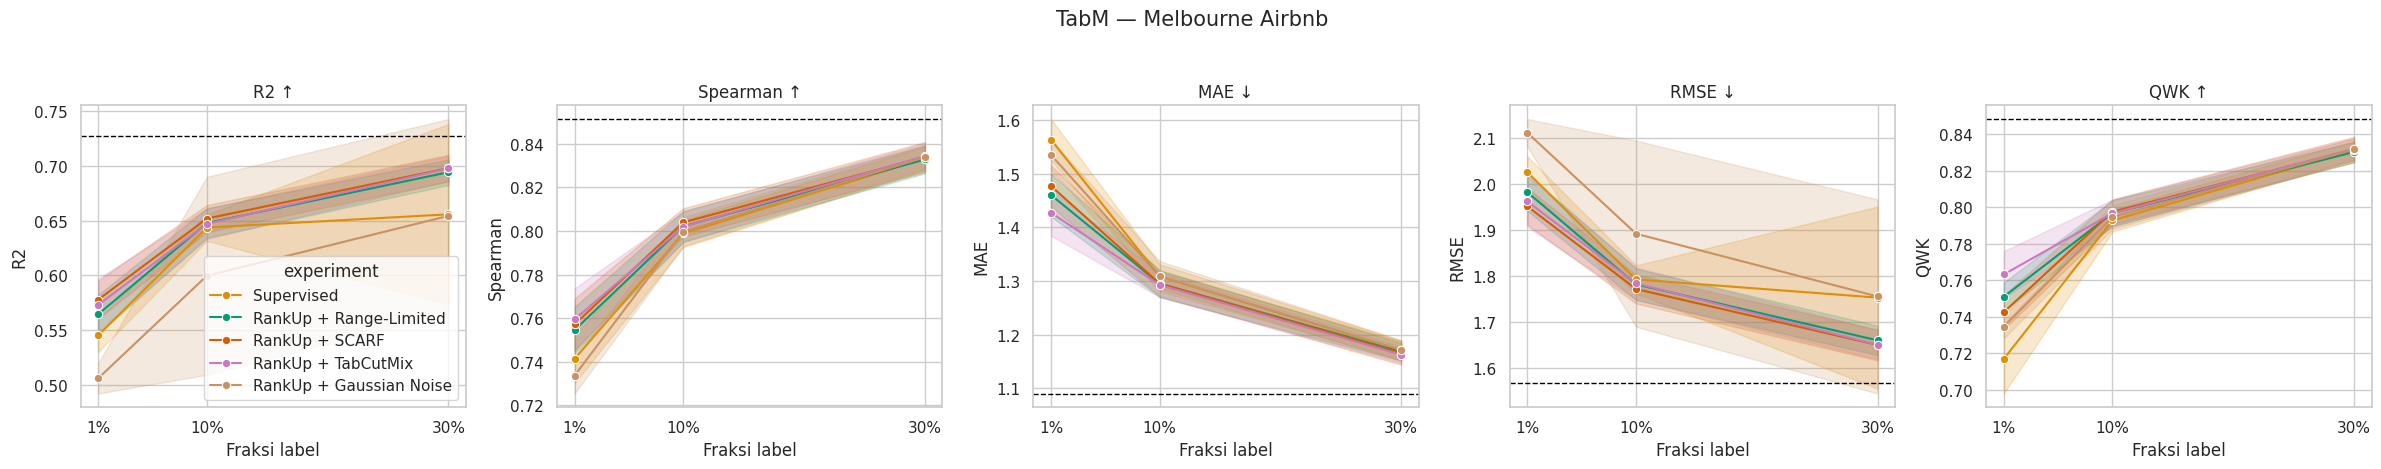

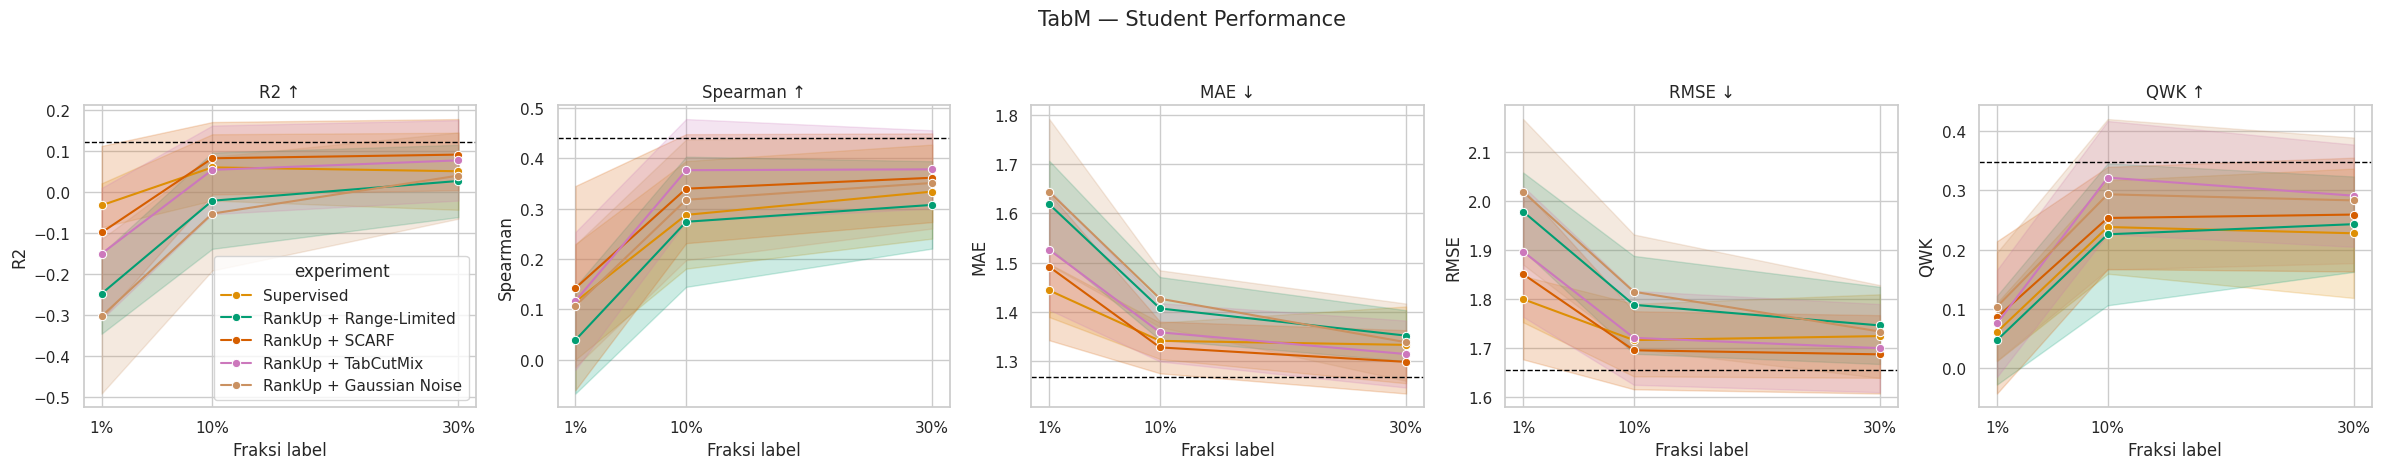

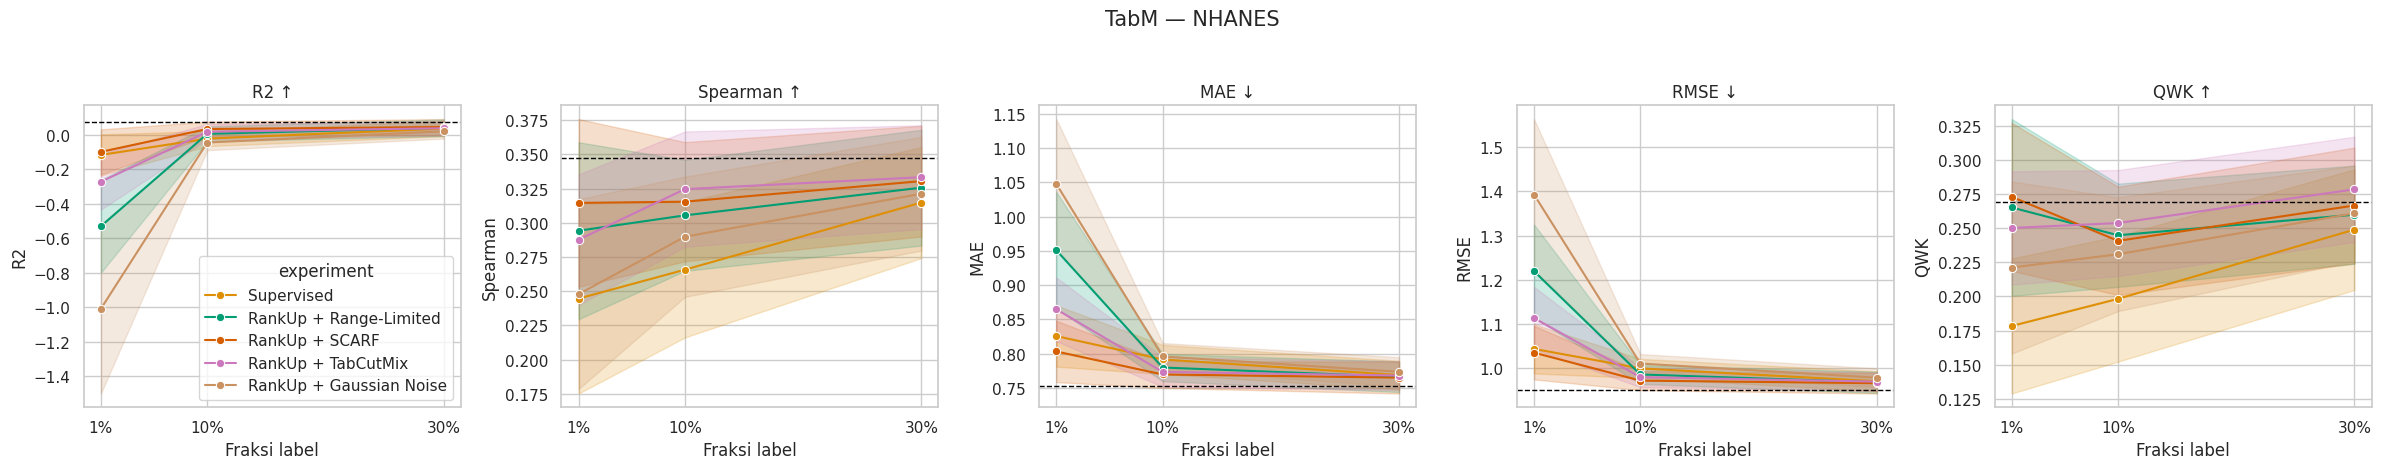

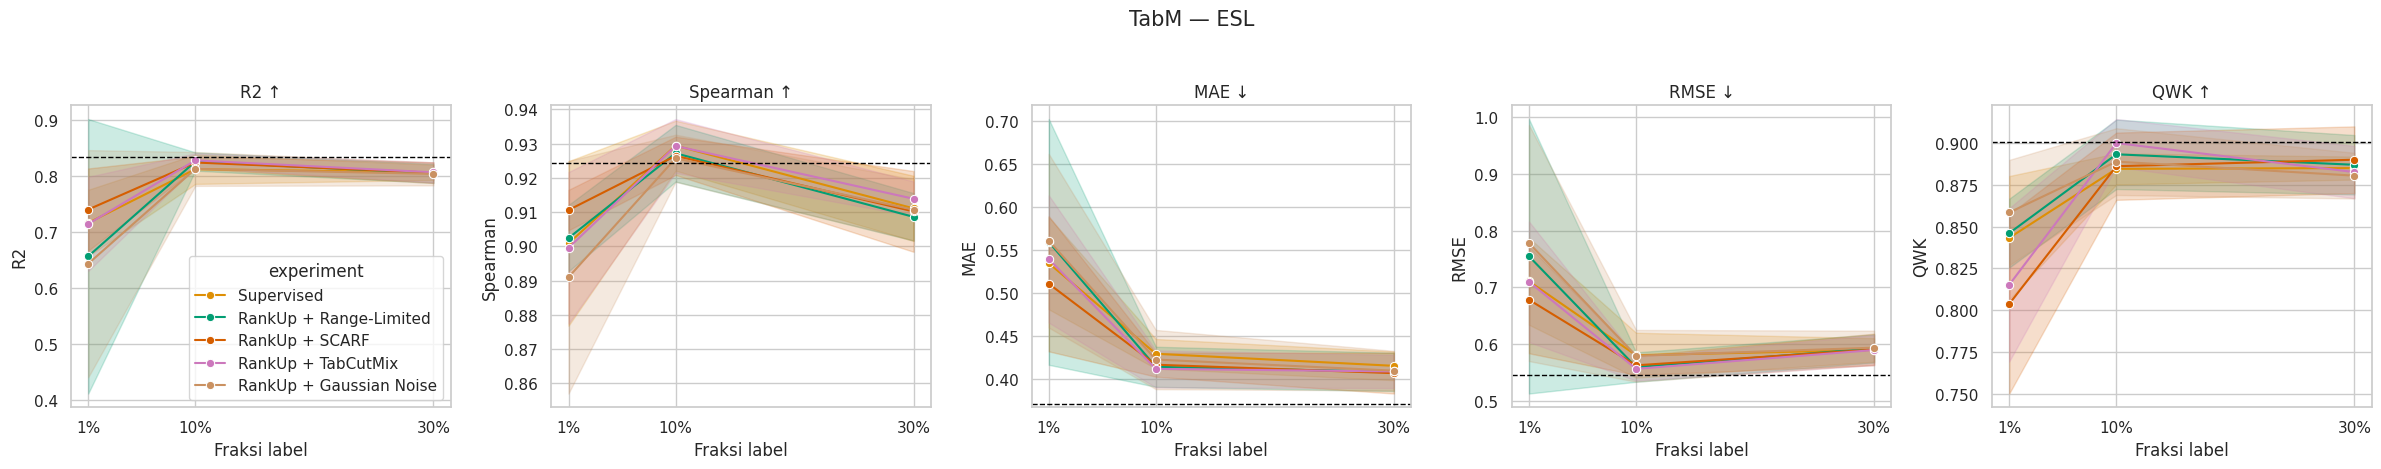

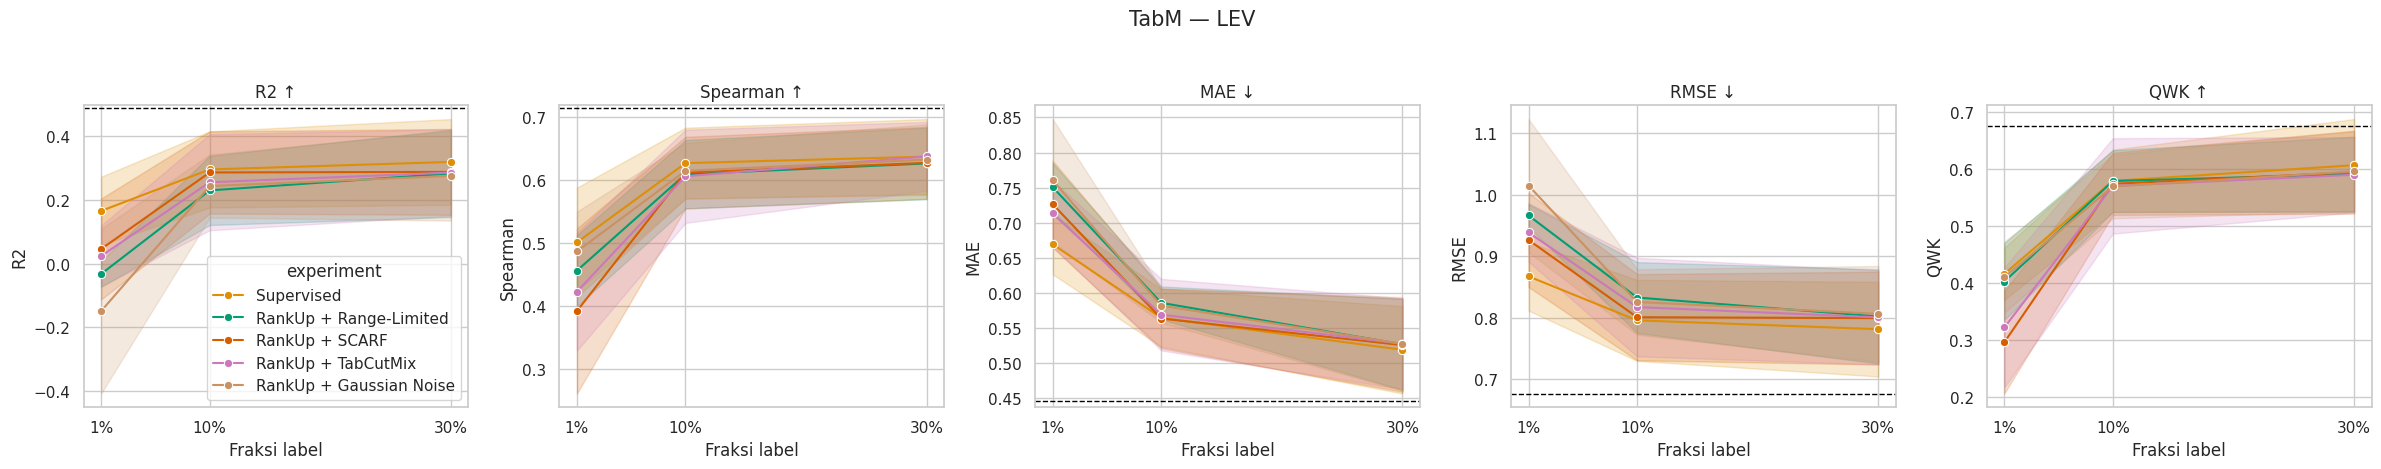

In [14]:
PALETTE = dict(zip(ALL_EXPERIMENTS, sns.color_palette("colorblind", len(ALL_EXPERIMENTS))))


def plot_fraction_sweep(dataset_name):
    subset = results_df.query("dataset == @dataset_name")
    fully = subset[subset["experiment"] == "Fully-Supervised"][METRICS].mean()
    sweep = subset[subset["experiment"] != "Fully-Supervised"]

    figure, axes = plt.subplots(1, 5, figsize=(24, 4.5))
    for index, (axis, metric) in enumerate(zip(axes, METRICS)):
        sns.lineplot(
            data=sweep, x="labeled_fraction", y=metric, hue="experiment",
            palette=PALETTE, marker="o", errorbar="sd", ax=axis,
        )
        axis.axhline(fully[metric], linestyle="--", color="black", linewidth=1, label="Fully-Supervised")
        axis.set_xticks(LABELED_FRACTIONS, labels=[f"{fraction:.0%}" for fraction in LABELED_FRACTIONS])
        axis.set_title(metric + (" ↓" if metric in ["MAE", "RMSE"] else " ↑"))
        axis.set_xlabel("Fraksi label")
        if index:
            axis.get_legend().remove()
    figure.suptitle(f"TabM — {dataset_name}", y=1.04, fontsize=15)
    figure.tight_layout()
    filename = DATASET_FILES[dataset_name][:-4]
    figure.savefig(OUTPUT_DIR / f"fraction_sweep_{filename}.png", dpi=150, bbox_inches="tight")
    plt.show()


for dataset_name in DATASET_FILES:
    plot_fraction_sweep(dataset_name)

## 9. File output

Setelah **Save & Run All**, unduh folder `rankup_tabm_fraction_results` dari tab Output Kaggle. Isinya:

- `metrics.csv`: lima metrik, fraksi label, jumlah label, seed, hardware, serta waktu training dan inference tiap run.
- `history.csv`: loss per epoch beserta breakdown ranking loss dan tingkat penerimaan pseudo-label.
- PNG sweep metrik terhadap fraksi label untuk setiap dataset.